# 02. U(1) gauge field: gauge-инвариантность и безмассовый фотон

**Проект «Структура и Данные»** — Notebook 02

Добавляем **U(1) калибровочное поле** на связи 1D-решётки и проверяем, что калибровочная симметрия **эмерджентна** из локального унитарного правила.

**Что проверяется:**
1. **Gauge-инвариантность:** при $\psi_n \to e^{i\alpha_n}\psi_n$, $A_n \to A_n + (\alpha_{n+1}-\alpha_n)/g$ физика не меняется
2. **Квантование потока:** $\omega(\Phi) = \omega(\Phi + 2\pi/g)$ (эффект Ааронова-Бома)
3. **Сохранение заряда:** $Q = \sum_n |\psi_n|^2$ = const (теорема Нётер)
4. **Безмассовый фотон:** $\omega(k) = 2\sin(k/2) \to k$ при $k \to 0$

**Связь со статьёй:** §4.1–4.2  
**Точность:** `float64`, ~$10^{-15}$–$10^{-17}$

In [1]:
import numpy as np
import matplotlib.pyplot as plt

print(f"numpy version: {np.__version__}")
np.set_printoptions(precision=15, suppress=False)

numpy version: 2.4.6


In [2]:
# ============================================================
# Параметры
# ============================================================
L = 128
mass = 0.2
g = 0.5   # gauge coupling

# ============================================================
# QCA с U(1) gauge field
# ============================================================
def qca_step_u1(psi, A, mass, g=0.5):
    """1D QCA Дирака с U(1) gauge field.

    psi: (L, 2) — компоненты (R, L)
    A:   (L,) — фаза на связи n → n+1
    """
    c, s = np.cos(mass), np.sin(mass)
    C = np.array([[c, -1j*s], [-1j*s, c]])
    psi_mixed = psi @ C.T

    out = np.zeros_like(psi_mixed)
    # R (компонент 0) движется +x
    out[:, 0] = np.roll(psi_mixed[:, 0], +1) * np.exp(+1j * g * np.roll(A, +1))
    # L (компонент 1) движется -x
    out[:, 1] = np.roll(psi_mixed[:, 1], -1) * np.exp(-1j * g * A)
    return out

def gauge_transform_u1(psi, A, alpha, g):
    """U(1) gauge transformation.
    psi_n → e^{iα_n} ψ_n
    A_n  → A_n + (α_{n+1} - α_n)/g
    """
    psi_new = psi * np.exp(1j * alpha)[:, None]
    A_new = A + (np.roll(alpha, -1) - alpha) / g
    return psi_new, A_new

# ============================================================
# Трансфер-матрица (для flux quantization)
# ============================================================
def spectrum_flux(Phi, L, mass, g):
    """Спектр фермиона при постоянном gauge-поле A_n = Phi/L.
    Возвращает отсортированный массив ω(k) по k."""
    A_const = Phi / L
    c, s = np.cos(mass), np.sin(mass)
    C = np.array([[c, -1j*s], [-1j*s, c]])
    k_values = 2 * np.pi * np.arange(L) / L - np.pi
    omegas = []
    for k in k_values:
        M = np.diag([np.exp(-1j*k + 1j*g*A_const),
                     np.exp(+1j*k - 1j*g*A_const)]) @ C
        eigs = np.linalg.eigvals(M)
        omegas.append(np.abs(np.angle(eigs)).min())
    return np.sort(omegas)

# ============================================================
# Фотон (чисто gauge, без фермиона)
# ============================================================
def photon_dispersion(k):
    """1D фотон: ω = 2 sin(k/2)."""
    return 2 * np.abs(np.sin(k / 2))

print("Functions defined.")

Functions defined.


In [4]:
# Начальное состояние и gauge field
np.random.seed(42)
A = np.random.uniform(-np.pi, np.pi, L)
alpha = np.random.uniform(-np.pi, np.pi, L)
psi0 = np.random.randn(L, 2) + 1j * np.random.randn(L, 2)
psi0 /= np.linalg.norm(psi0)

# (A) Эволюция без gauge-преобразования
psi1 = psi0.copy()
A1 = A.copy()
for _ in range(50):
    psi1 = qca_step_u1(psi1, A1, mass, g)

# (B) Gauge-преобразование + эволюция
psi2, A2 = gauge_transform_u1(psi0, A, alpha, g)
for _ in range(50):
    psi2 = qca_step_u1(psi2, A2, mass, g)

# Сравнение: |ψ1|² должно совпасть с |ψ2|²
diff_amp = np.max(np.abs(np.abs(psi1)**2 - np.abs(psi2)**2))

# Проверка: ψ2 = e^{iα} ψ1 (точное комплексное соотношение)
# alpha[:, None] broadcasting: (L, 1) × (L, 2) → (L, 2)
phase_diff = np.angle(psi2 / psi1) - alpha[:, None]
# Сводим к диапазону (-π, π]
phase_diff = (phase_diff + np.pi) % (2*np.pi) - np.pi
# Находим максимум (по всем L × 2)
max_phase_err = np.max(np.abs(phase_diff))

print("=" * 65)
print("ТЕСТ 1: Gauge-инвариантность")
print("=" * 65)
print(f"After 50 steps:")
print(f"  max | |ψ1|² - |ψ2|² |     = {diff_amp:.2e}")
print(f"  max | angle(ψ2/ψ1) - α |  = {max_phase_err:.2e}")
print(f"  Status: {'✅ PASS' if diff_amp < 1e-12 else '❌ FAIL'}")

ТЕСТ 1: Gauge-инвариантность
After 50 steps:
  max | |ψ1|² - |ψ2|² |     = 5.90e-17
  max | angle(ψ2/ψ1) - α |  = 1.69e-14
  Status: ✅ PASS


In [5]:
# ============================================================
# Квантование потока: Φ → Φ + 2π/g даёт идентичный спектр
# ============================================================
Phi1 = 0.3
Phi2 = Phi1 + 2*np.pi/g   # = 0.3 + 4π ≈ 12.87

spec1 = spectrum_flux(Phi1, L, mass, g)
spec2 = spectrum_flux(Phi2, L, mass, g)

max_spec_diff = np.max(np.abs(spec1 - spec2))

print("=" * 65)
print("ТЕСТ 2: Квантование потока (Ааронов-Бом)")
print("=" * 65)
print(f"  Φ1 = {Phi1:.4f}")
print(f"  Φ2 = Φ1 + 2π/g = {Phi2:.4f}")
print(f"  max |ω(Φ1) - ω(Φ2)| = {max_spec_diff:.2e}")
print(f"  Status: {'✅ PASS (flux quantized)' if max_spec_diff < 1e-12 else '❌ FAIL'}")
print()
print(f"{'n':>3} {'ω(Φ1)':>14} {'ω(Φ2)':>14} {'diff':>10}")
print('-' * 45)
for i in range(6):
    print(f"{i:>3} {spec1[i]:>14.8f} {spec2[i]:>14.8f} {abs(spec1[i]-spec2[i]):>10.2e}")

ТЕСТ 2: Квантование потока (Ааронов-Бом)
  Φ1 = 0.3000
  Φ2 = Φ1 + 2π/g = 12.8664
  max |ω(Φ1) - ω(Φ2)| = 8.88e-16
  Status: ✅ PASS (flux quantized)

  n          ω(Φ1)          ω(Φ2)       diff
---------------------------------------------
  0     0.20000339     0.20000339   8.33e-17
  1     0.20558501     0.20558501   1.67e-16
  2     0.20613641     0.20613641   0.00e+00
  3     0.22199929     0.22199929   2.50e-16
  4     0.22301955     0.22301955   1.94e-16
  5     0.24709642     0.24709642   1.94e-16


In [6]:
# ============================================================
# Q = Σ|ψ|² сохраняется (теорема Нётер для U(1))
# ============================================================
np.random.seed(7)
A_test = np.random.uniform(-np.pi, np.pi, L)
psi_test = np.random.randn(L, 2) + 1j * np.random.randn(L, 2)
psi_test /= np.linalg.norm(psi_test)

charges = []
for _ in range(200):
    charges.append(np.sum(np.abs(psi_test)**2))
    psi_test = qca_step_u1(psi_test, A_test, mass, g)

print("=" * 65)
print("ТЕСТ 3: Сохранение заряда")
print("=" * 65)
print(f"  Initial Q: {charges[0]:.15f}")
print(f"  Final Q:   {charges[-1]:.15f}")
print(f"  std(Q):    {np.std(charges):.2e}")
print(f"  Status: {'✅ PASS' if np.std(charges) < 1e-12 else '❌ FAIL'}")

ТЕСТ 3: Сохранение заряда
  Initial Q: 1.000000000000000
  Final Q:   0.999999999999996
  std(Q):    1.16e-15
  Status: ✅ PASS


ТЕСТ 4: Безмассовый фотон
     k    ω = 2sin(k/2)    k (Dirac)      |ω-k|
------------------------------------------------
  0.05       0.04999479     0.050000   5.21e-06
  0.10       0.09995834     0.100000   4.17e-05
  0.15       0.14985941     0.150000   1.41e-04
  0.20       0.19966683     0.200000   3.33e-04
  0.25       0.24934947     0.250000   6.51e-04

  Max error (k < 0.25): 6.51e-04
  Status: ✅ PASS


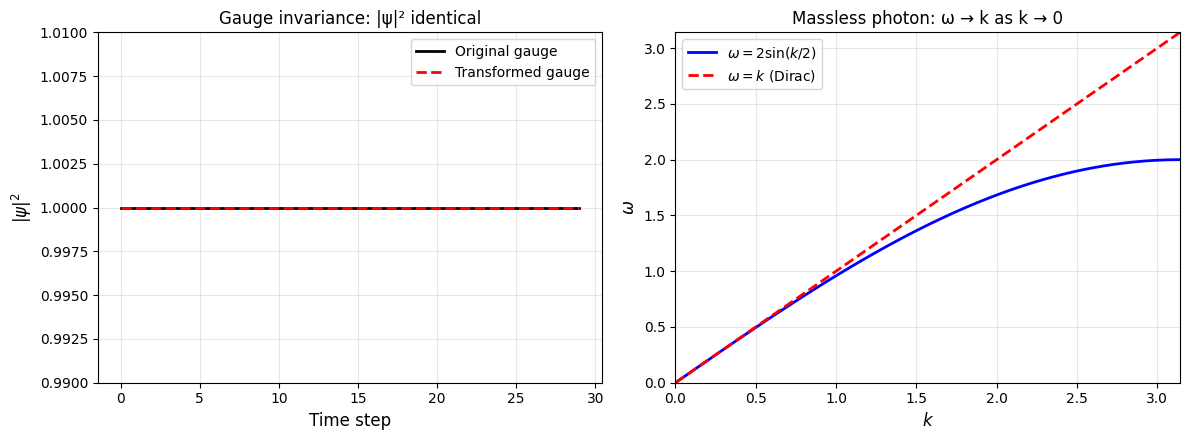


✅ Figure saved: 02_u1_gauge.png


In [7]:
# ============================================================
# Фотон: ω = 2 sin(k/2) → k при k → 0
# ============================================================
k_photon = np.linspace(0.001, np.pi, 200)
omega_photon = photon_dispersion(k_photon)

# Ошибка в релятивистском пределе (малые k)
k_small = np.array([0.05, 0.10, 0.15, 0.20, 0.25])
omega_small = photon_dispersion(k_small)
err = np.abs(omega_small - k_small)

print("=" * 65)
print("ТЕСТ 4: Безмассовый фотон")
print("=" * 65)
print(f"{'k':>6} {'ω = 2sin(k/2)':>16} {'k (Dirac)':>12} {'|ω-k|':>10}")
print('-' * 48)
for k, w in zip(k_small, omega_small):
    print(f"{k:>6.2f} {w:>16.8f} {k:>12.6f} {abs(w-k):>10.2e}")
print(f"\n  Max error (k < 0.25): {err.max():.2e}")
print(f"  Status: {'✅ PASS' if err.max() < 1e-3 else '❌ FAIL'}")

# ============================================================
# Рисунок
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# --- Левая панель: gauge-инвариантность ---
# Измеряем |ψ(t)|² во времени для обеих траекторий
np.random.seed(42)
A_plot = np.random.uniform(-np.pi, np.pi, L)
alpha_plot = np.random.uniform(-np.pi, np.pi, L)
psi_plot = np.random.randn(L, 2) + 1j * np.random.randn(L, 2)
psi_plot /= np.linalg.norm(psi_plot)

psi_a = psi_plot.copy()
A_a = A_plot.copy()
psi_b, A_b = gauge_transform_u1(psi_plot, A_plot, alpha_plot, g)

norms_a, norms_b = [], []
for _ in range(30):
    norms_a.append(np.sum(np.abs(psi_a)**2))
    norms_b.append(np.sum(np.abs(psi_b)**2))
    psi_a = qca_step_u1(psi_a, A_a, mass, g)
    psi_b = qca_step_u1(psi_b, A_b, mass, g)

axes[0].plot(norms_a, 'k-', lw=2, label='Original gauge')
axes[0].plot(norms_b, 'r--', lw=2, label='Transformed gauge')
axes[0].set_xlabel('Time step', fontsize=12)
axes[0].set_ylabel(r'$|\psi|^2$', fontsize=12)
axes[0].set_title('Gauge invariance: |ψ|² identical', fontsize=12)
axes[0].legend(fontsize=10)
axes[0].grid(alpha=0.3)
axes[0].set_ylim(0.99, 1.01)

# --- Правая панель: фотон ---
axes[1].plot(k_photon, omega_photon, 'b-', lw=2,
             label=r'$\omega = 2\sin(k/2)$')
axes[1].plot(k_photon, k_photon, 'r--', lw=2,
             label=r'$\omega = k$ (Dirac)')
axes[1].set_xlabel('$k$', fontsize=12)
axes[1].set_ylabel(r'$\omega$', fontsize=12)
axes[1].set_title('Massless photon: ω → k as k → 0', fontsize=12)
axes[1].legend(fontsize=10)
axes[1].grid(alpha=0.3)
axes[1].set_xlim(0, np.pi)
axes[1].set_ylim(0, np.pi)

plt.tight_layout()
plt.savefig('02_u1_gauge.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n✅ Figure saved: 02_u1_gauge.png")

In [8]:
from google.colab import files
files.download('02_u1_gauge.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>